# Experiment 4 — Variational Autoencoder (VAE) for Image Generation
**Aim:** Train a VAE, reconstruct images, generate new samples, and visualize the latent space.

### Dataset decision
The experiment sheet explicitly specifies MNIST handwritten digits. BattingCoach contains cricket-bat images, but using them would require a different image pipeline and would deviate from the prescribed MNIST experiment. This notebook therefore uses MNIST and records this deliberate choice.

## 1. Install TensorFlow

In [1]:
from importlib.metadata import version

for package in ('tensorflow', 'scikit-learn', 'matplotlib'):
    try:
        print(f"{package}: {version(package)}")
    except Exception as exc:
        print(f"{package}: unavailable ({exc})")


tensorflow: 2.22.0rc0
scikit-learn: 1.9.1
matplotlib: 3.11.2


## 2. Load and prepare MNIST

In [2]:
import tensorflow as tf, numpy as np, matplotlib.pyplot as plt
from tensorflow.keras import layers, Model
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
x_train = x_train.reshape((-1, 784))
x_test = x_test.reshape((-1, 784))
print(x_train.shape, x_test.shape)

(60000, 784) (10000, 784)


## 3. Build encoder, sampling layer and decoder

In [3]:
LATENT_DIM = 2
inputs = layers.Input(shape=(784,))
h = layers.Dense(256, activation="relu")(inputs)
h = layers.Dense(128, activation="relu")(h)
z_mean = layers.Dense(LATENT_DIM, name="z_mean")(h)
z_log_var = layers.Dense(LATENT_DIM, name="z_log_var")(h)

class Sampling(layers.Layer):
    def call(self, inputs):
        mean, log_var = inputs
        eps = tf.random.normal(shape=tf.shape(mean))
        return mean + tf.exp(0.5 * log_var) * eps

z = Sampling()([z_mean, z_log_var])
encoder = Model(inputs, [z_mean, z_log_var, z], name="encoder")

latent_inputs = layers.Input(shape=(LATENT_DIM,))
d = layers.Dense(128, activation="relu")(latent_inputs)
d = layers.Dense(256, activation="relu")(d)
outputs = layers.Dense(784, activation="sigmoid")(d)
decoder = Model(latent_inputs, outputs, name="decoder")

## 4. Define VAE loss and train

In [4]:
class VAE(Model):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder, self.decoder = encoder, decoder
        self.total_loss_tracker = tf.keras.metrics.Mean(name="loss")
        self.recon_tracker = tf.keras.metrics.Mean(name="reconstruction_loss")
        self.kl_tracker = tf.keras.metrics.Mean(name="kl_loss")
    def call(self, data, training=False):
        _, _, z = self.encoder(data, training=training)
        return self.decoder(z, training=training)
    @property
    def metrics(self):
        return [self.total_loss_tracker, self.recon_tracker, self.kl_tracker]
    def train_step(self, data):
        if isinstance(data, tuple): data = data[0]
        with tf.GradientTape() as tape:
            mean, log_var, z = self.encoder(data, training=True)
            reconstruction = self.decoder(z, training=True)
            recon = tf.reduce_mean(tf.reduce_sum(
                tf.keras.losses.binary_crossentropy(data, reconstruction), axis=-1))
            kl = -0.5 * tf.reduce_mean(tf.reduce_sum(
                1 + log_var - tf.square(mean) - tf.exp(log_var), axis=-1))
            loss = recon + kl
        grads = tape.gradient(loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.total_loss_tracker.update_state(loss)
        self.recon_tracker.update_state(recon)
        self.kl_tracker.update_state(kl)
        return {m.name: m.result() for m in self.metrics}
vae = VAE(encoder, decoder)
vae.compile(optimizer=tf.keras.optimizers.Adam(), loss="mse")
history = vae.fit(x_train, epochs=2, batch_size=128, validation_data=(x_test, x_test))

Epoch 1/2


  1/469 ━━━━━━━━━━━━━━━━━━━━ 7:22 945ms/step - kl_loss: 0.0720 - loss: 88.8621 - reconstruction_loss: 88.7901

  7/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - kl_loss: 0.2488 - loss: 86.5201 - reconstruction_loss: 86.2713    

 13/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - kl_loss: 1.7208 - loss: 81.4912 - reconstruction_loss: 79.7704

 19/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - kl_loss: 2.5703 - loss: 74.7709 - reconstruction_loss: 72.2005

 25/469 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - kl_loss: 2.6440 - loss: 68.1443 - reconstruction_loss: 65.5003

... (140 outputs left out)

456/469 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - kl_loss: 2.1019 - loss: 30.7978 - reconstruction_loss: 28.6960

461/469 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - kl_loss: 2.1050 - loss: 30.7881 - reconstruction_loss: 28.6830

466/469 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - kl_loss: 2.1080 - loss: 30.7857 - reconstruction_loss: 28.6777

469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - kl_loss: 2.1086 - loss: 30.7686 - reconstruction_loss: 28.6599 - val_kl_loss: 0.0000e+00 - val_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00


## 5. Plot training losses

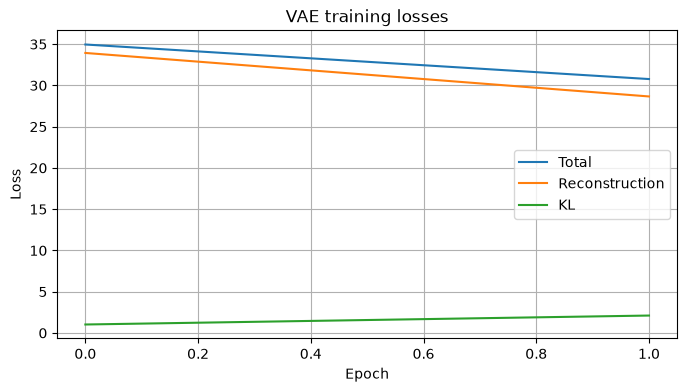

In [5]:
plt.figure(figsize=(8,4))
plt.plot(history.history["loss"], label="Total")
plt.plot(history.history["reconstruction_loss"], label="Reconstruction")
plt.plot(history.history["kl_loss"], label="KL")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("VAE training losses")
plt.legend(); plt.grid(True); plt.show()

## 6. Original vs reconstructed samples

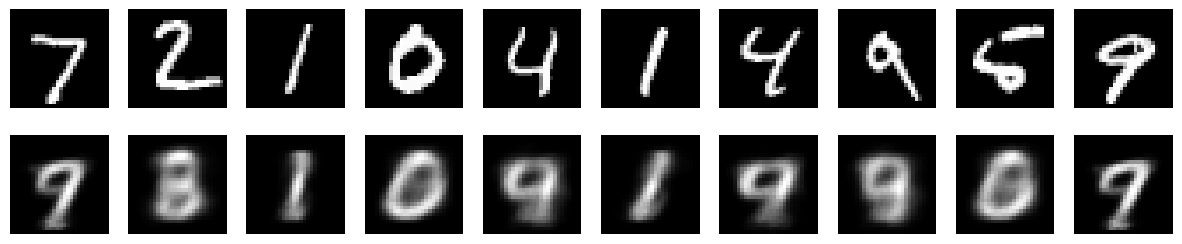

In [6]:
n=10
mean, log_var, z = encoder.predict(x_test[:n], verbose=0)
recon = decoder.predict(z, verbose=0).reshape(-1,28,28)
fig, axes = plt.subplots(2,n,figsize=(15,3))
for i in range(n):
    axes[0,i].imshow(x_test[i].reshape(28,28), cmap="gray"); axes[0,i].axis("off")
    axes[1,i].imshow(recon[i], cmap="gray"); axes[1,i].axis("off")
axes[0,0].set_ylabel("Original"); axes[1,0].set_ylabel("Reconstructed")
plt.show()

## 7. Generate new digits from random latent vectors

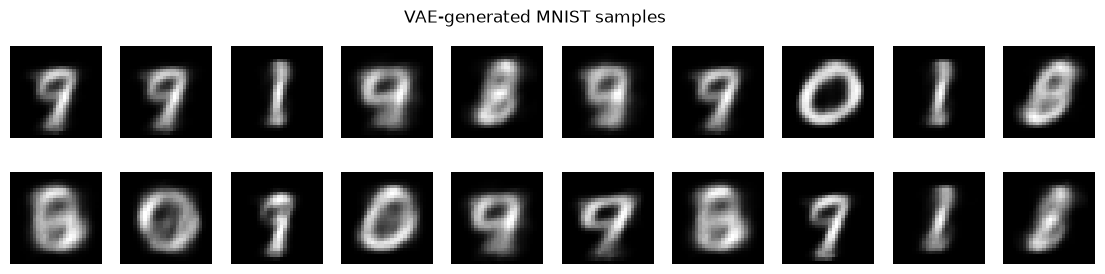

In [7]:
z_samples = np.random.normal(size=(20,LATENT_DIM)).astype("float32")
generated = decoder.predict(z_samples, verbose=0).reshape(-1,28,28)
fig, axes = plt.subplots(2,10,figsize=(14,3))
for ax, img in zip(axes.flat, generated):
    ax.imshow(img,cmap="gray"); ax.axis("off")
plt.suptitle("VAE-generated MNIST samples"); plt.show()

## 8. Visualize 2-D latent space

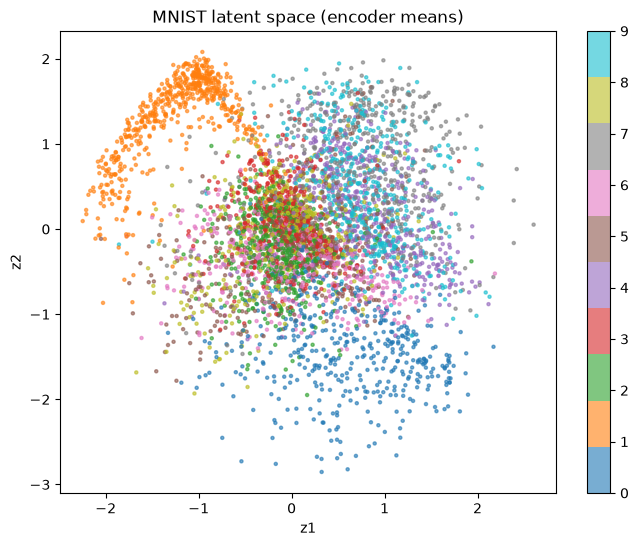

In [8]:
means, _, _ = encoder.predict(x_test[:5000], verbose=0)
plt.figure(figsize=(8,6))
scatter=plt.scatter(means[:,0], means[:,1], c=y_test[:5000], cmap="tab10", s=5, alpha=.6)
plt.colorbar(scatter, ticks=range(10)); plt.title("MNIST latent space (encoder means)")
plt.xlabel("z1"); plt.ylabel("z2"); plt.show()

## 9. Conclusion
Report reconstruction quality, whether digits are recognizable, how the latent space groups digit classes, and any training instability.